### **Does removing vocals help with tempo estimation?**

Now we use our tempo estimators on the test set. For each song we have
the original audio and an instrumental version made with Demucs.

We run Fourier, autocorrelation and the combined method on both versions
and compare them with the reference tempo. This lets us see if removing
the vocals improves, worsens or has little effect on our estimates.

The combined method was added after our first test run, so we treat it
as an extra exploratory comparison.


In [1]:
# Libraries
import csv
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
from scipy.stats import wilcoxon
from IPython.display import Markdown, display

# Function imports
from ballroom_dataset import PROJECT_ROOT, get_test_set
from tempo_estimator import estimate_tempo

params = {'legend.fontsize': 'x-large',
    'figure.figsize': (10, 5),
    'axes.labelsize': 'x-large',
    'axes.titlesize': 'x-large',
    'xtick.labelsize': 'x-large',
    'ytick.labelsize': 'x-large'}
plt.rcParams.update(params)

### **Parameters**

These are the same values we used in `tempo_estimator.ipynb`. We keep
them fixed for both audio versions and all songs. Window and hop sizes
are in seconds.

In [2]:
window_size = 0.04644
hop_size = 0.01161
gamma = 100
local_average_size = 0.1
tempogram_window_size = 5
tempogram_hop_size = 0.1
bpm_min = 30
bpm_max = 300

parameters = {
    "window_size": window_size,
    "hop_size": hop_size,
    "gamma": gamma,
    "local_average_size": local_average_size,
    "tempogram_window_size": tempogram_window_size,
    "tempogram_hop_size": tempogram_hop_size,
    "bpm_min": bpm_min,
    "bpm_max": bpm_max,
}

### **Loading the test set**

We use the 208 excerpts that we checked for strong vocals. The dataset
function gives us both audio paths, the dance style and the reference BPM.
Below we also show how many excerpts we have from each dance style.

In [3]:
test_set = get_test_set()
methods = [
    ("Fourier", "fourier"),
    ("Autocorrelation", "autocorr"),
    ("Combined", "combined"),
]
versions = [("Original", "original"), ("Instrumental", "instrumental")]
style_counts = Counter(track.dance_style for track in test_set)

results_path = PROJECT_ROOT / "results" / "test_tempo_results.csv"
plots_path = PROJECT_ROOT / "results" / "test_notebook"
plots_path.mkdir(parents=True, exist_ok=True)

print(f"Number of test excerpts: {len(test_set)}")

dataset_table = "| Dance style | Excerpts |\n| --- | ---: |\n"
for dance_style, count in sorted(style_counts.items()):
    dataset_table += f"| {dance_style} | {count} |\n"
display(Markdown(dataset_table))

Number of test excerpts: 208


| Dance style | Excerpts |
| --- | ---: |
| chachacha | 22 |
| jive | 28 |
| quickstep | 35 |
| rumba | 29 |
| samba | 28 |
| tango | 6 |
| viennesewaltz | 25 |
| waltz | 35 |


### **How we compare the estimates**

We use the same evaluation as in the development notebook. First we
calculate the absolute difference from the reference tempo:

$$
e = |\hat{\tau} - \tau_{\mathrm{reference}}|
$$

We label each estimate as correct, half, double or other, using a 4%
tolerance around each target. Strict accuracy only accepts the correct
category. We also show accuracy when half and double are accepted.
The absolute BPM error always uses the estimated tempo as it is.

For each song and method, we then calculate:

$$
\Delta e = e_{\mathrm{instrumental}} - e_{\mathrm{original}}
$$

A negative change means the instrumental version improved the estimate.
A positive change means it became worse, and zero means the error stayed
the same. The reference tempo is only used after estimating the BPM.

In [4]:
tolerance = 0.04

def tempo_category(estimated_bpm, reference_bpm):
    for category, factor in [("Correct", 1), ("Half", 0.5), ("Double", 2)]:
        target_bpm = reference_bpm * factor
        if abs(estimated_bpm - target_bpm) <= tolerance * target_bpm:
            return category
    return "Other"

### **Running all three methods on both audio versions**

We open the files with soundfile and use the sample rate from each file.
The original files are mono and the instrumentals are stereo, so we
average the instrumental channels to get mono before estimating tempo.

Each song gives us six estimates. We save one row per song and method,
with both versions together, in `results/test_tempo_results.csv`.

In [5]:
test_results = []

for index, track in enumerate(test_set, start=1):
    original, original_rate = sf.read(track.original_path)
    instrumental, instrumental_rate = sf.read(track.instrumental_path)

    if original.ndim == 2:
        original = np.mean(original, axis=1)
    if instrumental.ndim == 2:
        instrumental = np.mean(instrumental, axis=1)

    for method_name, method in methods:
        original_bpm, _ = estimate_tempo(original, original_rate, parameters, method)
        instrumental_bpm, _ = estimate_tempo(instrumental, instrumental_rate, parameters, method)

        original_error = abs(original_bpm - track.reference_bpm)
        instrumental_error = abs(instrumental_bpm - track.reference_bpm)

        test_results.append({
            "track_id": track.track_id,
            "dance_style": track.dance_style,
            "duplicate_group": track.duplicate_group,
            "method": method_name,
            "reference_bpm": track.reference_bpm,
            "original_bpm": original_bpm,
            "instrumental_bpm": instrumental_bpm,
            "original_error": original_error,
            "instrumental_error": instrumental_error,
            "error_change": instrumental_error - original_error,
            "original_category": tempo_category(original_bpm, track.reference_bpm),
            "instrumental_category": tempo_category(instrumental_bpm, track.reference_bpm),
        })

    if index % 10 == 0 or index == len(test_set):
        print(f"Processed {index}/{len(test_set)} excerpts")

with results_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=test_results[0].keys())
    writer.writeheader()
    writer.writerows(test_results)

print(f"Saved results to {results_path.relative_to(PROJECT_ROOT)}")

Processed 10/208 excerpts
Processed 20/208 excerpts
Processed 30/208 excerpts
Processed 40/208 excerpts
Processed 50/208 excerpts
Processed 60/208 excerpts
Processed 70/208 excerpts
Processed 80/208 excerpts
Processed 90/208 excerpts
Processed 100/208 excerpts
Processed 110/208 excerpts
Processed 120/208 excerpts
Processed 130/208 excerpts
Processed 140/208 excerpts
Processed 150/208 excerpts
Processed 160/208 excerpts
Processed 170/208 excerpts
Processed 180/208 excerpts
Processed 190/208 excerpts
Processed 200/208 excerpts
Processed 208/208 excerpts
Saved results to results/test_tempo_results.csv


### **Reading the saved results**

Now we read the saved estimates for the tables and plots below. If we
only want to redraw the plots later, we can run the setup cells, skip
the calculation above and start from this cell. After adding a method,
we need to rerun the calculation once to include it in the saved results.

In [6]:
with results_path.open(newline="", encoding="utf-8") as file:
    test_results = list(csv.DictReader(file))

numeric_columns = [
    "reference_bpm", "original_bpm", "instrumental_bpm",
    "original_error", "instrumental_error", "error_change",
]
for row in test_results:
    for column in numeric_columns:
        row[column] = float(row[column])

print(f"Loaded {len(test_results)} rows: {len(methods)} methods for each excerpt.")

Loaded 624 rows: 3 methods for each excerpt.


### **Results for the complete test set**

These tables show the results for each method and audio version. We
first count correct, half, double and other estimates, then compare
the mean BPM error and both accuracies.

In [7]:
summary_results = []

for method_name, _ in methods:
    method_results = [row for row in test_results if row["method"] == method_name]
    for version_name, version in versions:
        counts = Counter(row[f"{version}_category"] for row in method_results)
        count = len(method_results)

        summary_results.append({
            "method": method_name,
            "version": version_name,
            "count": count,
            "correct": counts["Correct"],
            "half": counts["Half"],
            "double": counts["Double"],
            "other": counts["Other"],
            "mae": np.mean([row[f"{version}_error"] for row in method_results]),
            "strict_accuracy": 100 * counts["Correct"] / count,
            "half_double_accuracy": 100 * (count - counts["Other"]) / count,
        })

count_table = "| Method | Audio | Excerpts | Correct | Half | Double | Other |\n"
count_table += "| --- | --- | ---: | ---: | ---: | ---: | ---: |\n"
accuracy_table = "| Method | Audio | Mean absolute error (BPM) | Strict accuracy | Accepting half/double |\n"
accuracy_table += "| --- | --- | ---: | ---: | ---: |\n"

for result in summary_results:
    count_table += (
        f"| {result['method']} | {result['version']} | {result['count']} "
        f"| {result['correct']} | {result['half']} | {result['double']} | {result['other']} |\n"
    )
    accuracy_table += (
        f"| {result['method']} | {result['version']} | {result['mae']:.2f} "
        f"| {result['strict_accuracy']:.1f}% | {result['half_double_accuracy']:.1f}% |\n"
    )

display(Markdown(count_table))
display(Markdown(accuracy_table))

| Method | Audio | Excerpts | Correct | Half | Double | Other |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| Fourier | Original | 208 | 80 | 0 | 88 | 40 |
| Fourier | Instrumental | 208 | 81 | 0 | 97 | 30 |
| Autocorrelation | Original | 208 | 80 | 39 | 56 | 33 |
| Autocorrelation | Instrumental | 208 | 83 | 44 | 57 | 24 |
| Combined | Original | 208 | 95 | 4 | 86 | 23 |
| Combined | Instrumental | 208 | 95 | 10 | 89 | 14 |


| Method | Audio | Mean absolute error (BPM) | Strict accuracy | Accepting half/double |
| --- | --- | ---: | ---: | ---: |
| Fourier | Original | 75.85 | 38.5% | 80.8% |
| Fourier | Instrumental | 69.60 | 38.9% | 85.6% |
| Autocorrelation | Original | 58.29 | 38.5% | 84.1% |
| Autocorrelation | Instrumental | 56.24 | 39.9% | 88.5% |
| Combined | Original | 60.84 | 45.7% | 88.9% |
| Combined | Instrumental | 56.35 | 45.7% | 93.3% |


### **How many excerpts improved?**

The overall averages do not show what happened to each song. Here we
count how many improved, worsened or kept the same absolute BPM error.

We also calculate a 95% bootstrap interval for the average error change.
We randomly sample 208 excerpts with replacement and calculate their
average change, repeating this 5,000 times. Each original stays paired
with its instrumental version. We use seed 42 to get the same result
when rerunning the notebook.

We take the 2.5th and 97.5th percentiles as the interval. If the whole
interval is below zero, it supports lower average error after removing
vocals. If it is above zero, it supports higher error. If it includes
zero, the direction of the average change is uncertain.

In [8]:
rng = np.random.default_rng(42)
bootstrap_indices = rng.integers(0, len(test_set), size=(5000, len(test_set)))
paired_results = []

for method_name, _ in methods:
    method_results = [row for row in test_results if row["method"] == method_name]
    changes = np.array([row["error_change"] for row in method_results])
    bootstrap_means = changes[bootstrap_indices].mean(axis=1)
    lower, upper = np.percentile(bootstrap_means, [2.5, 97.5])

    paired_results.append({
        "method": method_name,
        "improved": int(np.sum(changes < 0)),
        "worsened": int(np.sum(changes > 0)),
        "unchanged": int(np.sum(changes == 0)),
        "mean_change": changes.mean(),
        "lower": lower,
        "upper": upper,
    })

paired_table = "| Method | Improved | Worsened | Unchanged | Mean error change (BPM) | 95% bootstrap interval |\n"
paired_table += "| --- | ---: | ---: | ---: | ---: | --- |\n"
for result in paired_results:
    paired_table += (
        f"| {result['method']} | {result['improved']} | {result['worsened']} "
        f"| {result['unchanged']} | {result['mean_change']:+.2f} "
        f"| [{result['lower']:+.2f}, {result['upper']:+.2f}] |\n"
    )
display(Markdown(paired_table))

| Method | Improved | Worsened | Unchanged | Mean error change (BPM) | 95% bootstrap interval |
| --- | ---: | ---: | ---: | ---: | --- |
| Fourier | 39 | 20 | 149 | -6.25 | [-10.95, -1.89] |
| Autocorrelation | 47 | 26 | 135 | -2.05 | [-7.79, +3.50] |
| Combined | 50 | 32 | 126 | -4.49 | [-9.70, +0.34] |


### **Wilcoxon signed-rank test**

Now we also compare the paired absolute BPM errors using a Wilcoxon
signed-rank test. We use a two-sided test because removing vocals could
improve or worsen the estimates. The differences are instrumental error
minus original error, as above.

Pairs with no change are left out of the test. We use the normal
approximation with an adjustment for tied ranks, since we have repeated
values and many zero differences. The table shows how many pairs remain.

In [9]:
wilcoxon_results = []

for method_name, _ in methods:
    method_results = [row for row in test_results if row["method"] == method_name]
    changes = np.array([row["error_change"] for row in method_results])
    result = wilcoxon(
        changes,
        zero_method="wilcox",
        alternative="two-sided",
        method="asymptotic",
    )
    unchanged = int(np.sum(changes == 0))

    wilcoxon_results.append({
        "method": method_name,
        "pairs_used": len(changes) - unchanged,
        "unchanged": unchanged,
        "statistic": result.statistic,
        "p_value": result.pvalue,
    })

wilcoxon_table = "| Method | Pairs used | Unchanged pairs | W statistic | Unadjusted p-value |\n"
wilcoxon_table += "| --- | ---: | ---: | ---: | ---: |\n"
for result in wilcoxon_results:
    wilcoxon_table += (
        f"| {result['method']} | {result['pairs_used']} | {result['unchanged']} "
        f"| {result['statistic']:.1f} | {result['p_value']:.4f} |\n"
    )
display(Markdown(wilcoxon_table))


| Method | Pairs used | Unchanged pairs | W statistic | Unadjusted p-value |
| --- | ---: | ---: | ---: | ---: |
| Fourier | 59 | 149 | 502.5 | 0.0035 |
| Autocorrelation | 73 | 135 | 1102.0 | 0.1697 |
| Combined | 82 | 126 | 1249.0 | 0.0329 |


### **Original error compared with instrumental error**

Each dot is one excerpt. Dots below the diagonal have a lower error
after removing vocals. Dots above it have a higher error. Dots on the
line have the same error for both versions.

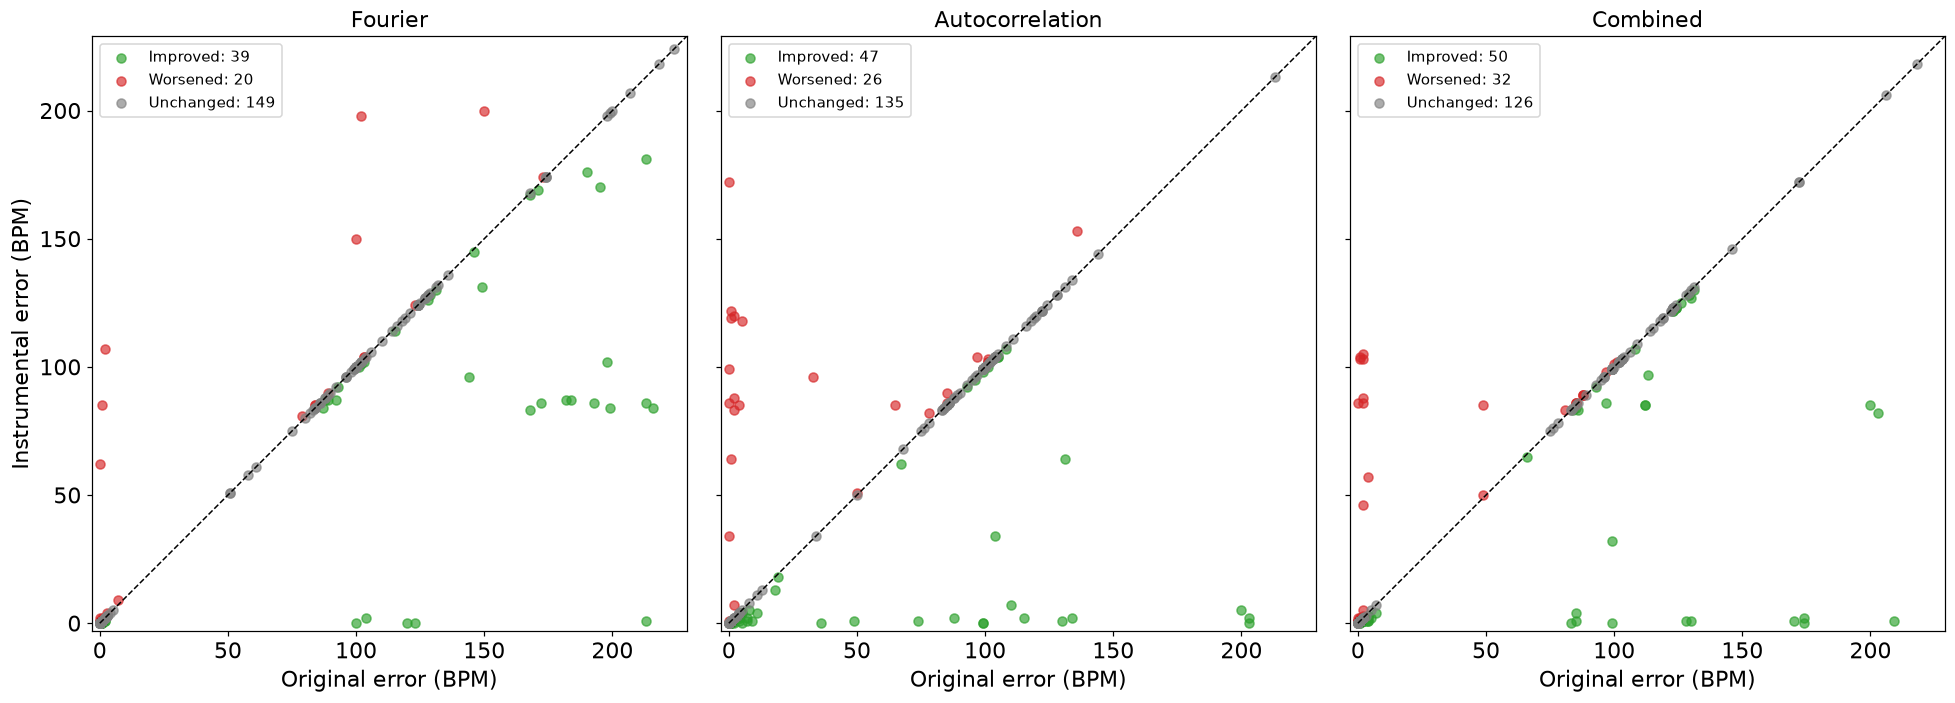

In [10]:
fig, axes = plt.subplots(1, len(methods), figsize=(6 * len(methods), 6), sharex=True, sharey=True)
error_limit = max(max(row["original_error"], row["instrumental_error"])
                  for row in test_results) + 5

for ax, (method_name, _) in zip(axes, methods):
    method_results = [row for row in test_results if row["method"] == method_name]

    for label, color in [("Improved", "tab:green"), ("Worsened", "tab:red"), ("Unchanged", "gray")]:
        if label == "Improved":
            points = [row for row in method_results if row["error_change"] < 0]
        elif label == "Worsened":
            points = [row for row in method_results if row["error_change"] > 0]
        else:
            points = [row for row in method_results if row["error_change"] == 0]

        ax.scatter([row["original_error"] for row in points],
                   [row["instrumental_error"] for row in points],
                   color=color, alpha=0.65, s=35, label=f"{label}: {len(points)}")

    ax.plot([0, error_limit], [0, error_limit], color="black", linestyle="--", linewidth=1)
    ax.set_xlim(-3, error_limit)
    ax.set_ylim(-3, error_limit)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Original error (BPM)")
    ax.set_title(method_name)
    ax.legend(fontsize=10)

axes[0].set_ylabel("Instrumental error (BPM)")
plt.tight_layout()
fig.savefig(plots_path / "tempo_errors.png", dpi=200, bbox_inches="tight")
plt.show()

### **Comparing the accuracies**

Now we compare the two audio versions using both accuracy measures.
The left plot uses strict accuracy. The right plot also accepts half
and double tempo estimates.

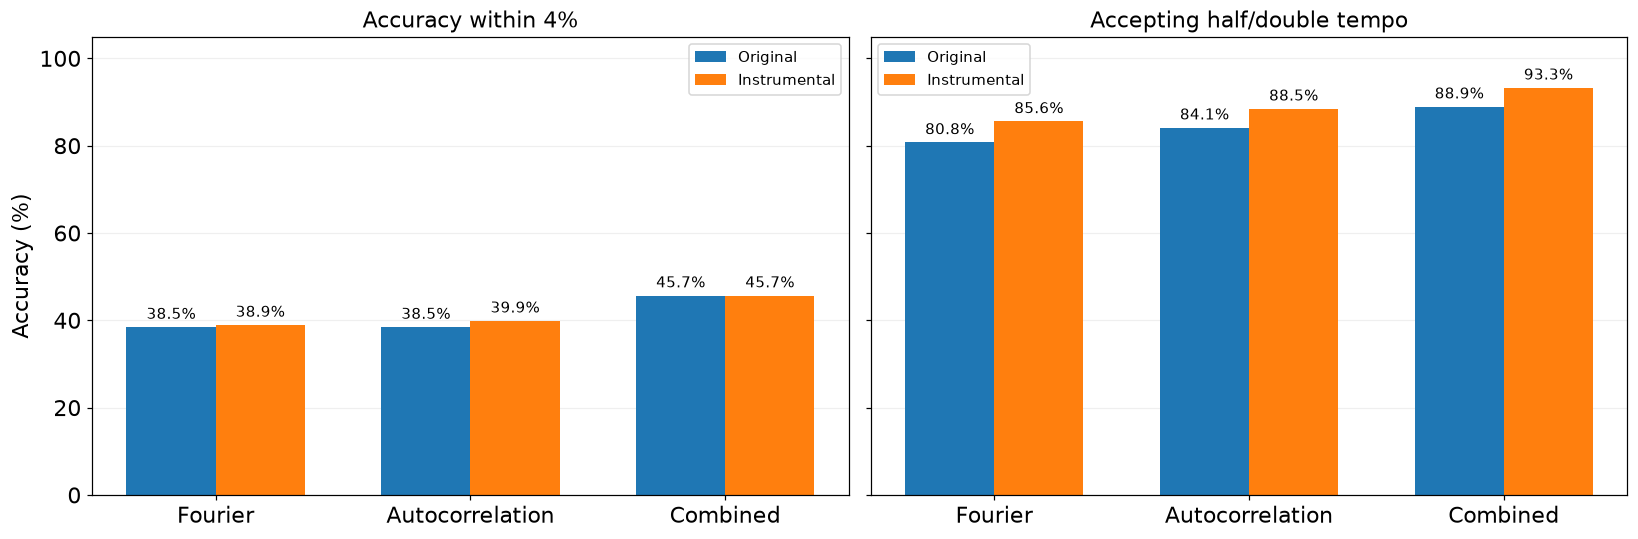

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
positions = np.arange(len(methods))
width = 0.35

for ax, metric, title in zip(
    axes,
    ["strict_accuracy", "half_double_accuracy"],
    ["Accuracy within 4%", "Accepting half/double tempo"],
):
    for index, (version_name, _) in enumerate(versions):
        values = [next(row[metric] for row in summary_results
                       if row["method"] == method_name and row["version"] == version_name)
                  for method_name, _ in methods]
        bars = ax.bar(positions + (index - 0.5) * width, values, width, label=version_name)
        ax.bar_label(bars, labels=[f"{value:.1f}%" for value in values], padding=3, fontsize=10)

    ax.set_xticks(positions, [name for name, _ in methods])
    ax.set_ylim(0, 105)
    ax.set_title(title)
    ax.legend(fontsize=10)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

axes[0].set_ylabel("Accuracy (%)")
plt.tight_layout()
fig.savefig(plots_path / "tempo_accuracy.png", dpi=200, bbox_inches="tight")
plt.show()

### **Results by dance style**

Here we compare the errors and accuracies for each dance style. We
include the number of excerpts because the styles have different
amounts of data. For example, the test set only has six tango excerpts.

In [12]:
style_results = []

for dance_style in sorted(style_counts):
    for method_name, _ in methods:
        rows = [row for row in test_results
                if row["dance_style"] == dance_style and row["method"] == method_name]
        count = len(rows)
        original_counts = Counter(row["original_category"] for row in rows)
        instrumental_counts = Counter(row["instrumental_category"] for row in rows)

        style_results.append({
            "dance_style": dance_style,
            "method": method_name,
            "count": count,
            "original_mae": np.mean([row["original_error"] for row in rows]),
            "instrumental_mae": np.mean([row["instrumental_error"] for row in rows]),
            "mean_change": np.mean([row["error_change"] for row in rows]),
            "original_strict": 100 * original_counts["Correct"] / count,
            "instrumental_strict": 100 * instrumental_counts["Correct"] / count,
            "original_half_double": 100 * (count - original_counts["Other"]) / count,
            "instrumental_half_double": 100 * (count - instrumental_counts["Other"]) / count,
        })

style_error_table = "| Dance style | Method | Excerpts | Original error (BPM) | Instrumental error (BPM) | Change (BPM) |\n"
style_error_table += "| --- | --- | ---: | ---: | ---: | ---: |\n"
style_accuracy_table = "| Dance style | Method | Original strict | Instrumental strict | Original half/double | Instrumental half/double |\n"
style_accuracy_table += "| --- | --- | ---: | ---: | ---: | ---: |\n"

for result in style_results:
    style_error_table += (
        f"| {result['dance_style']} | {result['method']} | {result['count']} "
        f"| {result['original_mae']:.2f} | {result['instrumental_mae']:.2f} "
        f"| {result['mean_change']:+.2f} |\n"
    )
    style_accuracy_table += (
        f"| {result['dance_style']} | {result['method']} "
        f"| {result['original_strict']:.1f}% | {result['instrumental_strict']:.1f}% "
        f"| {result['original_half_double']:.1f}% | {result['instrumental_half_double']:.1f}% |\n"
    )

display(Markdown(style_error_table))
display(Markdown(style_accuracy_table))

| Dance style | Method | Excerpts | Original error (BPM) | Instrumental error (BPM) | Change (BPM) |
| --- | --- | ---: | ---: | ---: | ---: |
| chachacha | Fourier | 22 | 120.55 | 120.55 | +0.00 |
| chachacha | Autocorrelation | 22 | 50.45 | 55.32 | +4.86 |
| chachacha | Combined | 22 | 120.27 | 120.00 | -0.27 |
| jive | Fourier | 28 | 21.36 | 24.32 | +2.96 |
| jive | Autocorrelation | 28 | 33.75 | 39.50 | +5.75 |
| jive | Combined | 28 | 6.25 | 13.96 | +7.71 |
| quickstep | Fourier | 35 | 7.97 | 5.14 | -2.83 |
| quickstep | Autocorrelation | 35 | 90.63 | 90.91 | +0.29 |
| quickstep | Combined | 35 | 14.03 | 25.74 | +11.71 |
| rumba | Fourier | 29 | 104.28 | 104.24 | -0.03 |
| rumba | Autocorrelation | 29 | 78.66 | 82.14 | +3.48 |
| rumba | Combined | 29 | 98.97 | 98.93 | -0.03 |
| samba | Fourier | 28 | 117.82 | 115.36 | -2.46 |
| samba | Autocorrelation | 28 | 68.25 | 60.96 | -7.29 |
| samba | Combined | 28 | 91.36 | 84.93 | -6.43 |
| tango | Fourier | 6 | 128.00 | 127.50 | -0.50 |
| tango | Autocorrelation | 6 | 89.67 | 67.50 | -22.17 |
| tango | Combined | 6 | 129.83 | 107.50 | -22.33 |
| viennesewaltz | Fourier | 25 | 13.04 | 5.88 | -7.16 |
| viennesewaltz | Autocorrelation | 25 | 14.08 | 18.24 | +4.16 |
| viennesewaltz | Combined | 25 | 2.56 | 4.20 | +1.64 |
| waltz | Fourier | 35 | 138.00 | 108.54 | -29.46 |
| waltz | Autocorrelation | 35 | 51.89 | 35.51 | -16.37 |
| waltz | Combined | 35 | 87.74 | 51.20 | -36.54 |


| Dance style | Method | Original strict | Instrumental strict | Original half/double | Instrumental half/double |
| --- | --- | ---: | ---: | ---: | ---: |
| chachacha | Fourier | 0.0% | 0.0% | 100.0% | 100.0% |
| chachacha | Autocorrelation | 59.1% | 54.5% | 90.9% | 95.5% |
| chachacha | Combined | 0.0% | 0.0% | 95.5% | 100.0% |
| jive | Fourier | 82.1% | 78.6% | 96.4% | 92.9% |
| jive | Autocorrelation | 60.7% | 53.6% | 96.4% | 100.0% |
| jive | Combined | 92.9% | 82.1% | 96.4% | 92.9% |
| quickstep | Fourier | 91.4% | 91.4% | 91.4% | 91.4% |
| quickstep | Autocorrelation | 5.7% | 8.6% | 85.7% | 88.6% |
| quickstep | Combined | 85.7% | 74.3% | 94.3% | 94.3% |
| rumba | Fourier | 0.0% | 0.0% | 93.1% | 93.1% |
| rumba | Autocorrelation | 13.8% | 10.3% | 96.6% | 96.6% |
| rumba | Combined | 0.0% | 0.0% | 96.6% | 96.6% |
| samba | Fourier | 7.1% | 10.7% | 60.7% | 60.7% |
| samba | Autocorrelation | 28.6% | 35.7% | 82.1% | 82.1% |
| samba | Combined | 17.9% | 21.4% | 85.7% | 85.7% |
| tango | Fourier | 0.0% | 0.0% | 100.0% | 100.0% |
| tango | Autocorrelation | 33.3% | 33.3% | 83.3% | 83.3% |
| tango | Combined | 0.0% | 16.7% | 100.0% | 100.0% |
| viennesewaltz | Fourier | 88.0% | 92.0% | 88.0% | 92.0% |
| viennesewaltz | Autocorrelation | 76.0% | 72.0% | 76.0% | 72.0% |
| viennesewaltz | Combined | 100.0% | 96.0% | 100.0% | 96.0% |
| waltz | Fourier | 2.9% | 2.9% | 42.9% | 71.4% |
| waltz | Autocorrelation | 42.9% | 57.1% | 65.7% | 85.7% |
| waltz | Combined | 25.7% | 42.9% | 60.0% | 88.6% |


### **Where did removing vocals help?**

This plot shows the average error change for each dance style and
method. Blue means the error decreased and red means it increased.
The numbers are changes in BPM, so negative values mean improvement.

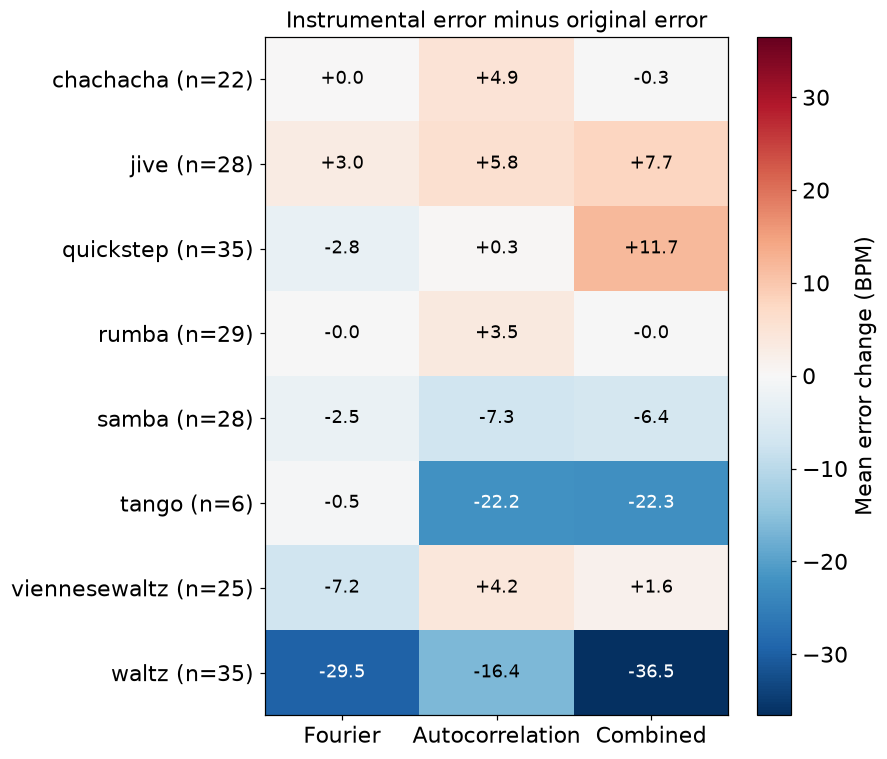

In [13]:
dance_styles = sorted(style_counts)
changes_by_style = np.array([
    [next(row["mean_change"] for row in style_results
          if row["dance_style"] == dance_style and row["method"] == method_name)
     for method_name, _ in methods]
    for dance_style in dance_styles
])
color_limit = max(1, np.abs(changes_by_style).max())

fig, ax = plt.subplots(figsize=(8, 7))
heatmap = ax.imshow(changes_by_style, cmap="RdBu_r", vmin=-color_limit, vmax=color_limit, aspect="auto")
ax.set_xticks(np.arange(len(methods)), [name for name, _ in methods])
ax.set_yticks(np.arange(len(dance_styles)),
              [f"{style} (n={style_counts[style]})" for style in dance_styles])
ax.set_title("Instrumental error minus original error")

for i in range(len(dance_styles)):
    for j in range(len(methods)):
        value = changes_by_style[i, j]
        text_color = "white" if abs(value) > 0.6 * color_limit else "black"
        ax.text(j, i, f"{value:+.1f}", ha="center", va="center", color=text_color, fontsize=12)

fig.colorbar(heatmap, ax=ax, label="Mean error change (BPM)")
plt.tight_layout()
fig.savefig(plots_path / "tempo_by_style.png", dpi=200, bbox_inches="tight")
plt.show()

### **What the results show**

Below we summarise the average change and how many excerpts improved
or worsened. We use the bootstrap interval to help judge whether the
average change has a clear direction.

In [14]:
for result in paired_results:
    original_summary = next(row for row in summary_results
                            if row["method"] == result["method"] and row["version"] == "Original")
    instrumental_summary = next(row for row in summary_results
                                if row["method"] == result["method"] and row["version"] == "Instrumental")

    if result["upper"] < 0:
        interval_text = "The interval is below zero, which supports lower average error after removing vocals."
    elif result["lower"] > 0:
        interval_text = "The interval is above zero, which supports higher average error after removing vocals."
    else:
        interval_text = "The interval includes zero, so the direction of the average change is uncertain."

    display(Markdown(
        f"**{result['method']}:** The mean error changed from {original_summary['mae']:.2f} "
        f"to {instrumental_summary['mae']:.2f} BPM, a change of {result['mean_change']:+.2f} BPM. "
        f"Removing vocals improved {result['improved']} excerpts, worsened {result['worsened']} "
        f"and left {result['unchanged']} with the same error. "
        f"The 95% bootstrap interval is [{result['lower']:+.2f}, {result['upper']:+.2f}] BPM. "
        f"{interval_text}"
    ))

**Fourier:** The mean error changed from 75.85 to 69.60 BPM, a change of -6.25 BPM. Removing vocals improved 39 excerpts, worsened 20 and left 149 with the same error. The 95% bootstrap interval is [-10.95, -1.89] BPM. The interval is below zero, which supports lower average error after removing vocals.

**Autocorrelation:** The mean error changed from 58.29 to 56.24 BPM, a change of -2.05 BPM. Removing vocals improved 47 excerpts, worsened 26 and left 135 with the same error. The 95% bootstrap interval is [-7.79, +3.50] BPM. The interval includes zero, so the direction of the average change is uncertain.

**Combined:** The mean error changed from 60.84 to 56.35 BPM, a change of -4.49 BPM. Removing vocals improved 50 excerpts, worsened 32 and left 126 with the same error. The 95% bootstrap interval is [-9.70, +0.34] BPM. The interval includes zero, so the direction of the average change is uncertain.